# Bayesian Cumulative-Shrinkage Factor Analysis of the Lung Cancer Data

This notebook applies the JAX `GibbsCSP` implementation to `lung.npy`. The model is $x_i=B\eta_i+\epsilon_i$, with a cumulative shrinkage process prior on the loading-column variances and truncation level $H=50$.

The analysis includes posterior sampling and ESS diagnostics, factor-dimension selection using the CSP $H^*$ posterior and 95% marginal HPD intervals, Rotation-Sign-Permutation (RSP) alignment, loading-column norms, and factor-score plots for four sample groups. Factor selection is performed in the original prior coordinates; RSP is used only to obtain a consistent orientation for visualization.

In [1]:
import os

MODE = "cpu"
if MODE not in {"cpu", "gpu"}:
    raise ValueError('MODE must be "cpu" or "gpu".')
os.environ["JAX_PLATFORMS"] = "cpu" if MODE == "cpu" else "cuda,cpu"

import jax

backend = jax.default_backend()
expected_backends = {"cpu"} if MODE == "cpu" else {"gpu", "cuda"}
if backend not in expected_backends:
    raise RuntimeError(
        f"JAX backend is {backend!r}, expected one of {sorted(expected_backends)} "
        f"for MODE={MODE!r}; restart the kernel and run all cells."
    )
print("Backend:", backend)
print("Devices:", jax.devices())

Backend: cpu
Devices: [CpuDevice(id=0)]


## 1. Data and CSP Settings

The data contain 56 samples and 5,000 genes. Samples are ordered as Carcinoid (20), Colon (13), Normal (17), and Small cell (6). Every gene is already standardized to mean zero and unit standard deviation, so fitting uses `center=False`.

The CSP settings follow the paper and repository demos, except that `b_sigma=1.0` as requested. The conservative truncation allows at most $H-1=49$ active factors.

In [2]:
import hashlib
import sys
import time
from pathlib import Path

%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np

root = next(
    (d for d in (Path.cwd(), *Path.cwd().parents) if (d / "CSP_JAX").is_dir()),
    None,
)
if root is None:
    raise FileNotFoundError("Could not locate the repository root containing CSP_JAX/.")
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from CSP_JAX import GibbsCSP, ess_summary

H = 50
ALPHA = 5.0
A_THETA = 2.0
B_THETA = 2.0
THETA_INF = 0.05
A_SIGMA = 1.0
B_SIGMA = 1.0
N_ITER = 20000
BURN_IN = 10000
THIN = 10
LEVEL = 0.95
SEED = 2026

X = np.load(root / "lung" / "lung.npy", allow_pickle=False)
if X.shape != (56, 5000):
    raise ValueError(f"Expected X.shape == (56, 5000), got {X.shape}.")
if not np.isfinite(X).all():
    raise ValueError("X contains NaN or infinity.")
column_means = X.mean(axis=0, dtype=np.float64)
column_stds = X.std(axis=0, dtype=np.float64)
np.testing.assert_allclose(column_means, 0.0, rtol=0.0, atol=1e-12)
np.testing.assert_allclose(column_stds, 1.0, rtol=0.0, atol=1e-12)

GROUPS = (
    ("Carcinoid", 0, 20, "orange", "s"),
    ("Colon", 20, 33, "blue", "o"),
    ("Normal", 33, 50, "green", "^"),
    ("Small cell", 50, 56, "black", "*"),
)
plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 140,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": "#5b6472",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 10,
})
np.set_printoptions(precision=4, suppress=True, linewidth=150)

print(f"Python: {sys.executable}")
print(f"Repository: {root}")
print(f"X: {X.shape}, dtype={X.dtype}, range=({X.min():.4f}, {X.max():.4f})")
print(f"max |column mean|={np.abs(column_means).max():.3e}; "
      f"column std range=({column_stds.min():.6f}, {column_stds.max():.6f})")
print(f"H={H}, alpha={ALPHA}, a_theta=b_theta={A_THETA}, "
      f"theta_inf={THETA_INF}, a_sigma={A_SIGMA}, b_sigma={B_SIGMA}")
print(f"MCMC: {N_ITER} sweeps, burn-in={BURN_IN}, thin={THIN}, seed={SEED}")

Python: C:\Users\kexio\miniconda3\python.exe
Repository: C:\Users\kexio\Desktop\GitHub\CSP_BFM
X: (56, 5000), dtype=float64, range=(-6.6776, 7.1188)
max |column mean|=8.921e-17; column std range=(1.000000, 1.000000)
H=50, alpha=5.0, a_theta=b_theta=2.0, theta_inf=0.05, a_sigma=1.0, b_sigma=1.0
MCMC: 20000 sweeps, burn-in=10000, thin=10, seed=2026


## 2. CSP Gibbs Posterior Sampling

The sampler runs 20,000 sweeps, discards the first 10,000 as burn-in, and retains every 10th draw thereafter, yielding 1,000 posterior draws. The chain stores loadings, idiosyncratic variances, and the CSP active-factor count $H^*$.

In [3]:
t0 = time.perf_counter()
gs = GibbsCSP(
    H=H,
    alpha=ALPHA,
    a_theta=A_THETA,
    b_theta=B_THETA,
    theta_inf=THETA_INF,
    a_sigma=A_SIGMA,
    b_sigma=B_SIGMA,
    center=False,
    n_iter=N_ITER,
    burn_in=BURN_IN,
    thin=THIN,
    seed=SEED,
    verbose=True,
).fit(X)
gs_wall = time.perf_counter() - t0

S = gs.B_samples_.shape[0]
assert S == (N_ITER - BURN_IN) // THIN == 1000
assert gs.B_samples_.shape == (S, X.shape[1], H)
assert gs.sigma2_samples_.shape == (S, X.shape[1])
assert gs.H_star_samples_.shape == (S,)
assert np.isfinite(gs.B_samples_).all()
assert np.isfinite(gs.sigma2_samples_).all()
assert gs.seed_ == SEED
assert 0 <= gs.H_star_samples_.min() and gs.H_star_samples_.max() <= H - 1
print(
    f"GibbsCSP: kept={S}, scan={gs.runtime_sec_:.2f}s, "
    f"wall={gs_wall:.2f}s (including compilation)"
)
print(f"Stored loading draws: {gs.B_samples_.nbytes / 2**30:.3f} GiB")

GS_CSP: sweep 2104/20000


GS_CSP: sweep 4208/20000


GS_CSP: sweep 6312/20000


GS_CSP: sweep 8416/20000


GS_CSP: sweep 10526/20000


...

GS_CSP: sweep 14734/20000


GS_CSP: sweep 16838/20000


GS_CSP: sweep 18942/20000


GS_CSP: sweep 20000/20000


GibbsCSP: kept=1000, scan=1702.40s, wall=1715.42s (including compilation)
Stored loading draws: 0.931 GiB


## 3. Active-Factor Posterior and ESS

The CSP rule estimates dimension from the posterior of $H^*=\sum_h 1(z_h>h)$. The loading and $H^*$ chains are summarized separately because $z$ is drawn against the pre-update loading matrix within each sweep: retained pairs are offset by half a sweep and are not synchronous joint posterior draws.

Bulk ESS is computed from raw draws. To bound temporary ArviZ memory use, loading and noise-variance diagnostics use every 25th gene (200 genes); the complete $H^*$ chain is always used. This subsetting does not affect factor selection.

H* posterior: mean=2.0000, median=2.0, 95% equal-tailed CI=(2.0, 2.0)
n_factors(method='h_star') = 2


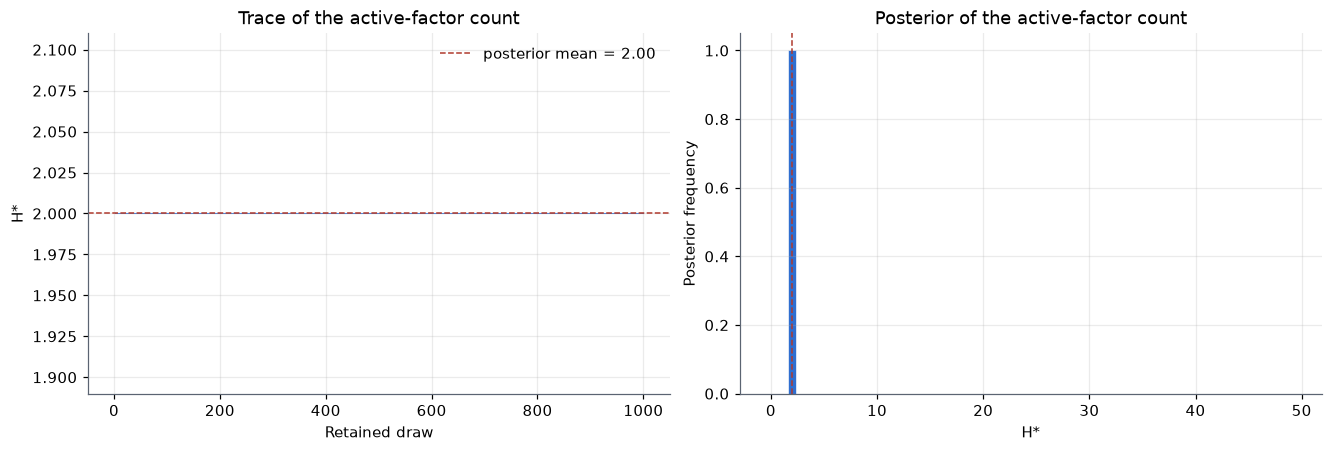

In [4]:
h_summary = gs.h_star_summary(level=LEVEL)
r_h_star = gs.n_factors(method="h_star")
hs = gs.H_star_samples_
print(
    f"H* posterior: mean={h_summary['mean']:.4f}, "
    f"median={h_summary['median']:.1f}, "
    f"95% equal-tailed CI=({h_summary['ci'][0]:.1f}, {h_summary['ci'][1]:.1f})"
)
print(f"n_factors(method='h_star') = {r_h_star}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.0), constrained_layout=True)
axes[0].plot(np.arange(1, S + 1), hs, color="#2f6fd0", lw=0.7, alpha=0.8)
axes[0].axhline(h_summary["mean"], color="#b03a2e", ls="--", lw=1.0,
                label=f"posterior mean = {h_summary['mean']:.2f}")
axes[0].set_xlabel("Retained draw")
axes[0].set_ylabel("H*")
axes[0].set_title("Trace of the active-factor count")
axes[0].legend(frameon=False)

counts = np.bincount(hs, minlength=H)
axes[1].bar(np.arange(H), counts / S, width=0.82, color="#2f6fd0",
            edgecolor="white", linewidth=0.4)
axes[1].axvline(h_summary["median"], color="#b03a2e", ls="--", lw=1.0)
axes[1].set_xlabel("H*")
axes[1].set_ylabel("Posterior frequency")
axes[1].set_title("Posterior of the active-factor count")
plt.show()

In [5]:
ESS_STRIDE = 25
ess_gs = ess_summary(
    gs.B_samples_[:, ::ESS_STRIDE, :],
    gs.sigma2_samples_[:, ::ESS_STRIDE],
    hs=gs.H_star_samples_,
    method="bulk",
)
print(f"Bulk ESS summary (every {ESS_STRIDE}th gene for B and sigma2; full H* chain):")
for name, stats in ess_gs.items():
    print(
        f"  {name}: min={stats['min']:.1f}, median={stats['median']:.1f}, "
        f"mean={stats['mean']:.1f}, max={stats['max']:.1f}, "
        f"draws={stats['n_draws']}"
    )
print("Constant or nearly constant columns can require separate ESS inspection.")

Bulk ESS summary (every 25th gene for B and sigma2; full H* chain):
  B: min=2.2, median=62.6, mean=78.4, max=875.0, draws=1000
  sigma2: min=707.3, median=963.1, mean=950.7, max=1125.8, draws=1000
  H_star: min=1000.0, median=1000.0, mean=1000.0, max=1000.0, draws=1000
Constant or nearly constant columns can require separate ESS inspection.


## 4. Marginal HPD Factor Selection in the Original Coordinates

As a complementary summary, a loading entry is active when its 95% shortest marginal HPD interval excludes zero. A column is counted as active when at least one of its 5,000 entries is active. The implementation matches `BaseCSP.active_entries()` but processes 250 genes at a time to avoid converting and sorting all loading draws in float64 at once.

Active factors (95% marginal HPD): 2
Proportion of active entries by column:
[0.4182 0.0192 0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.
 0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.
 0.     0.     0.     0.     0.     0.     0.     0.    ]


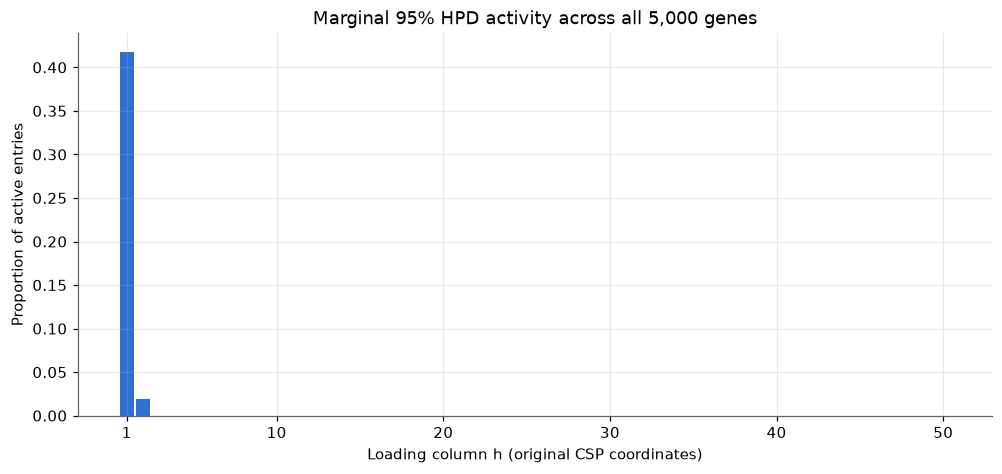

In [6]:
def gibbs_active_entries_hpd(draws, level=0.95, chunk_genes=250):
    draws = np.asarray(draws)
    S_, p, H_ = draws.shape
    if S_ < 2:
        raise ValueError("At least two draws are required.")
    m = int(np.ceil(level * S_))
    active = np.empty((p, H_), dtype=bool)
    for start in range(0, p, chunk_genes):
        stop = min(start + chunk_genes, p)
        sorted_draws = np.sort(
            np.asarray(draws[:, start:stop, :], dtype=np.float64), axis=0
        )
        if m >= S_:
            lo, hi = sorted_draws[0], sorted_draws[-1]
        else:
            widths = sorted_draws[m - 1:] - sorted_draws[:S_ - m + 1]
            idx = np.argmin(widths, axis=0)
            lo = np.take_along_axis(sorted_draws, idx[None], axis=0)[0]
            hi = np.take_along_axis(
                sorted_draws, (idx + m - 1)[None], axis=0
            )[0]
        active[start:stop] = (lo > 0) | (hi < 0)
    return active


gs_active = gibbs_active_entries_hpd(gs.B_samples_, level=LEVEL)
gs_activity = gs_active.mean(axis=0, dtype=np.float64)
r_hpd = int(gs_active.any(axis=0).sum())
assert gs_active.shape == (X.shape[1], H)
print(f"Active factors (95% marginal HPD): {r_hpd}")
print("Proportion of active entries by column:")
print(gs_activity)

fig, ax = plt.subplots(figsize=(9, 4.2), constrained_layout=True)
ax.bar(np.arange(1, H + 1), gs_activity, color="#2f6fd0", width=0.85)
ax.set_xlabel("Loading column h (original CSP coordinates)")
ax.set_ylabel("Proportion of active entries")
ax.set_title("Marginal 95% HPD activity across all 5,000 genes")
ax.set_xticks([1, 10, 20, 30, 40, 50])
plt.show()

## 5. RSP Alignment and Factor Scores

Varimax plus sign/permutation post-processing is applied only after the original-coordinate diagnostics. With $H=50$, the automatic assignment backend uses Optax's Hungarian solver. Alignment updates `B_hat_` to the mean of the aligned draws but must leave the raw draws, $H^*$ chain, noise-variance estimate, and Monte Carlo covariance mean unchanged.

The covariance invariance check uses a zero-copy digest rather than an additional 200 MB copy of the 5,000 by 5,000 matrix.

In [7]:
def array_digest(a):
    a = np.asarray(a)
    if not a.flags.c_contiguous:
        raise ValueError("array_digest expects a C-contiguous array")
    return hashlib.blake2b(memoryview(a).cast("B"), digest_size=16).hexdigest()


B_digest_before = array_digest(gs.B_samples_)
H_star_before = gs.H_star_samples_.copy()
sigma2_hat_before = gs.sigma2_hat_.copy()
n_factors_before = gs.n_factors()
t0 = time.perf_counter()
Sigma_mc_digest_before = array_digest(gs.Sigma_mc_)
sigma_mc_wall = time.perf_counter() - t0

t0 = time.perf_counter()
gs.align_factors(assignment_backend="auto", verbose=False)
gs_rsp_wall = time.perf_counter() - t0
result = gs.rsp_result_
status = int(result.status_code)
assert status in (1, 2, 3)
alignment_summary = {
    "status": status,
    "stop_reason": result.diagnostics["stop_reason"],
    "n_iter": int(result.n_iter),
    "loss_final": float(result.loss_final),
}

assert array_digest(gs.B_samples_) == B_digest_before
np.testing.assert_array_equal(gs.H_star_samples_, H_star_before)
np.testing.assert_array_equal(gs.sigma2_hat_, sigma2_hat_before)
assert array_digest(gs.Sigma_mc_) == Sigma_mc_digest_before
assert gs.n_factors() == n_factors_before
assert gs.B_aligned_.shape == gs.B_samples_.shape
assert result.transforms.shape == (S, H, H)
assert np.isfinite(gs.B_aligned_).all()
np.testing.assert_allclose(
    gs.B_hat_, gs.B_aligned_.mean(axis=0), rtol=2e-5, atol=2e-6
)
print(
    f"RSP: status={status}, stop={alignment_summary['stop_reason']}, "
    f"iterations={alignment_summary['n_iter']}, "
    f"final loss={alignment_summary['loss_final']:.6g}"
)
print(f"RSP wall={gs_rsp_wall:.2f}s; Sigma_mc_ initial computation={sigma_mc_wall:.2f}s")
print("Raw loadings, H*, sigma2_hat_, Sigma_mc_, and the default factor count are unchanged.")
print("Diagnostics:", result.diagnostics)

RSP: status=1, stop=converged_threshold, iterations=30, final loss=1.04228e+07
RSP wall=2230.57s; Sigma_mc_ initial computation=157.00s
Raw loadings, H*, sigma2_hat_, Sigma_mc_, and the default factor count are unchanged.
Diagnostics: {'initial_reference_near_zero': False, 'sp_path': 'elim', 'assignment_backend': 'auto', 'rotated': True, 'precision': 'float32', 'stop_reason': 'converged_threshold', 'nonfinite_fields': ()}


In [8]:
scores = gs.sample_factors(
    X,
    return_eta=True,
    return_eta_aligned=True,
    seed=SEED,
    batch_size=32,
)
eta_raw = scores["eta_sample"]
eta_aligned = scores["eta_sample_aligned"]
eta_mean = eta_aligned.mean(axis=0, dtype=np.float64)
assert eta_raw.shape == eta_aligned.shape == (S, H, X.shape[0])
assert eta_mean.shape == (H, X.shape[0])
assert np.isfinite(eta_raw).all() and np.isfinite(eta_aligned).all()

draw_index = 0
common_raw = gs.B_samples_[draw_index] @ eta_raw[draw_index]
common_aligned = gs.B_aligned_[draw_index] @ eta_aligned[draw_index]
np.testing.assert_allclose(common_aligned, common_raw, rtol=2e-4, atol=2e-4)
relative_difference = (
    np.linalg.norm(common_aligned - common_raw) / np.linalg.norm(common_raw)
)
print("RSP reconstruction check passed.")
print(f"Relative B@eta difference for draw {draw_index}: {relative_difference:.3e}")
print("Aligned score draws:", eta_aligned.shape, "(S, H, n)")

RSP reconstruction check passed.
Relative B@eta difference for draw 0: 3.023e-07
Aligned score draws: (1000, 50, 56) (S, H, n)


## 6. Loading-Column Norms and Sample Factor Scores

Loading norms use the RSP-aligned posterior mean. The score plot averages conditional factor-score draws in the aligned coordinates. The original $H^*$ definition is not transferred to these rotated columns.

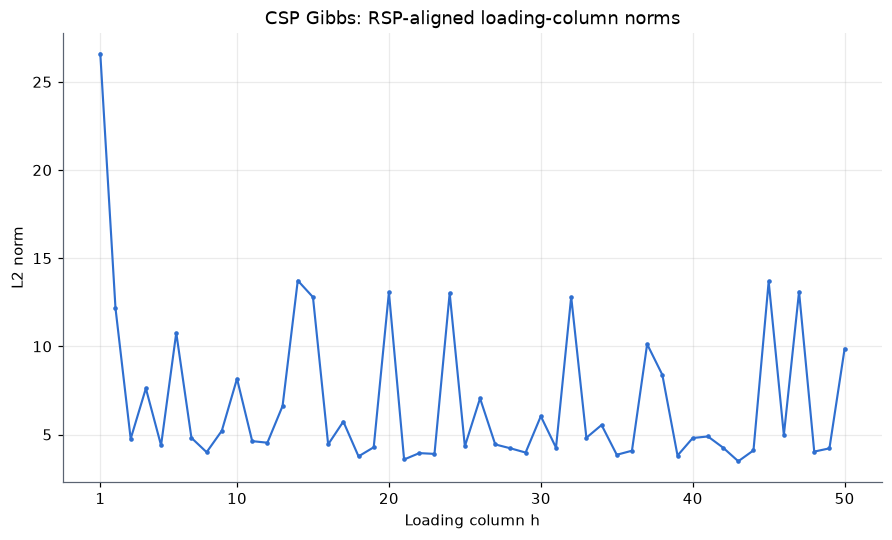

In [9]:
column_index = np.arange(1, H + 1)
norm_gs = np.linalg.norm(np.asarray(gs.B_hat_, dtype=np.float64), axis=0)
assert norm_gs.shape == (H,) and np.isfinite(norm_gs).all()

fig, ax = plt.subplots(figsize=(8, 4.8), constrained_layout=True)
ax.plot(column_index, norm_gs, color="#2f6fd0", lw=1.4, marker=".", ms=4)
ax.set_title("CSP Gibbs: RSP-aligned loading-column norms")
ax.set_xlabel("Loading column h")
ax.set_ylabel("L2 norm")
ax.set_xticks([1, 10, 20, 30, 40, 50])
plt.show()

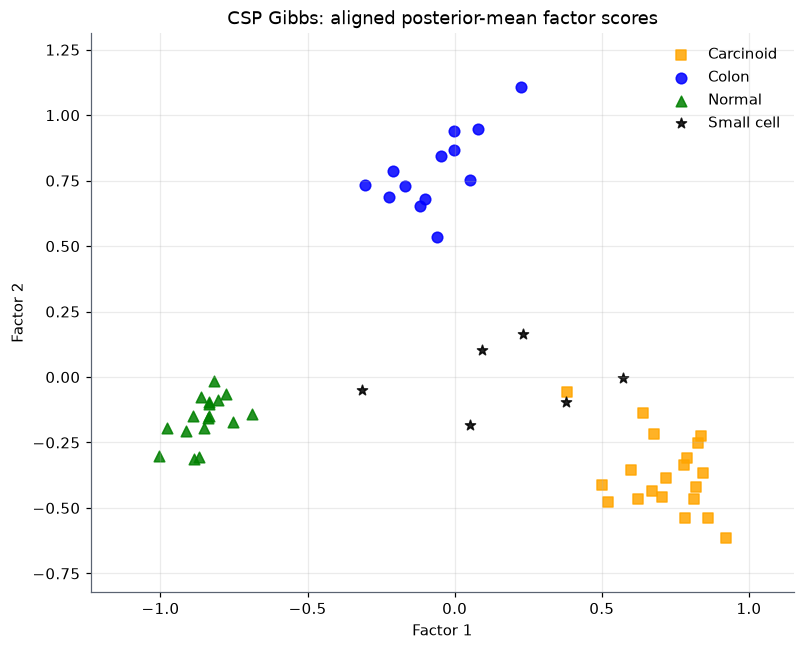

In [10]:
fig, ax = plt.subplots(figsize=(7.2, 5.8), constrained_layout=True)
for label, start, stop, color, marker in GROUPS:
    ax.scatter(
        eta_mean[0, start:stop],
        eta_mean[1, start:stop],
        c=color,
        marker=marker,
        s=48,
        alpha=0.85,
        label=label,
    )
ax.set_title("CSP Gibbs: aligned posterior-mean factor scores")
ax.set_xlabel("Factor 1")
ax.set_ylabel("Factor 2")
ax.margins(x=0.12, y=0.12)
ax.legend(frameon=False, loc="best")
plt.show()

## 7. Run Summary

The following summary is generated from the actual CSP fit. The two factor counts answer different questions: the CSP $H^*$ posterior is the primary dimension-selection rule, while the marginal HPD count summarizes entrywise credible intervals in the original coordinates.

In [11]:
print("Lung cancer CSP analysis summary")
print("=" * 34)
print(
    f"Data: n={X.shape[0]}, p={X.shape[1]}; H={H}; "
    f"alpha={ALPHA:g}; a_sigma={A_SIGMA:g}; b_sigma={B_SIGMA:g}"
)
print(
    f"Gibbs: {N_ITER} sweeps, burn-in={BURN_IN}, thin={THIN}, "
    f"kept={S}; fit wall={gs_wall:.1f}s"
)
print(
    f"H*: mean={h_summary['mean']:.4f}, median={h_summary['median']:.1f}, "
    f"95% CI=({h_summary['ci'][0]:.1f}, {h_summary['ci'][1]:.1f}); "
    f"integer rule={r_h_star}"
)
print(f"95% marginal HPD active-factor count: {r_hpd}")
print(
    f"Bulk ESS median: B (200-gene subset)={ess_gs['B']['median']:.1f}, "
    f"sigma2 (same subset)={ess_gs['sigma2']['median']:.1f}, "
    f"H* (full chain)={ess_gs['H_star']['median']:.1f}"
)
print(
    f"RSP: status={alignment_summary['status']}, "
    f"stop={alignment_summary['stop_reason']}, "
    f"iterations={alignment_summary['n_iter']}, wall={gs_rsp_wall:.1f}s"
)
print("All requested fits, figures, and numerical checks completed.")

Lung cancer CSP analysis summary
Data: n=56, p=5000; H=50; alpha=5; a_sigma=1; b_sigma=1
Gibbs: 20000 sweeps, burn-in=10000, thin=10, kept=1000; fit wall=1715.4s
H*: mean=2.0000, median=2.0, 95% CI=(2.0, 2.0); integer rule=2
95% marginal HPD active-factor count: 2
Bulk ESS median: B (200-gene subset)=62.6, sigma2 (same subset)=963.1, H* (full chain)=1000.0
RSP: status=1, stop=converged_threshold, iterations=30, wall=2230.6s
All requested fits, figures, and numerical checks completed.
